# STM samples - what one record actually looks like

Companion to `tools/analyze_stm.py`, which measures the **corpus**. This notebook looks at
**individual records**: the 14-slice image cube that conditions the model, the molecule it is
paired with, and the checks that say the two belong together.

**Kernel / environment.** On **Roihu (x86_64)** start Jupyter from the `python-pytorch/2.10`
module, with the project's rdkit overlay on the path:

```bash
module load python-pytorch/2.10
export PYTHONPATH="/projappl/project_2001912/ters-overlay-x86_64:$PWD"
jupyter lab
```

The older `im2g` venv and `$HOME/.cache/ters-overlay` are **aarch64 builds and cannot run
here** (`the image's architecture (arm64) could not run on the host's (amd64)`). The module
supplies everything except rdkit; the overlay supplies rdkit and nothing else.

Nothing below imports `datasets` or `evaluation` directly -- `tools/analyze_stm.py` loads what
it needs past those packages' `__init__`, so a kernel without `torch_geometric` or `fcd_torch`
still works.

| section | |
|---|---|
| 1 | The file: layout, attributes, and what a "record" is |
| 2 | One record: all 14 z-slices, twice - shared scale and per-slice scale |
| 3 | A gallery: cube and molecule side by side |
| 4 | The z-envelope - the property `NormalizeStmCube` exists to preserve |
| 5 | Image / coordinate alignment: **measured here, not assumed** |
| 6 | The corpus-level figures from `tools/analyze_stm.py` |

## 0 - Setup

In [1]:
import json, os, sys
from collections import Counter

import numpy as np
import h5py
import torch
import matplotlib.pyplot as plt

# Find the repo root from wherever the kernel started, so `tools.` imports resolve.
REPO = os.getcwd()
while REPO != '/' and not os.path.exists(os.path.join(REPO, 'tools', 'analyze_stm.py')):
    REPO = os.path.dirname(REPO)
sys.path.insert(0, REPO)

# REUSE, all three. The element map comes from datasets/preprocess_stm.py and is never
# retyped here (it has to agree with datasets_config.py's atom_decoder), and `prep` is the
# same heavy-atom depiction helper tools/visualize_local.py:35 uses for the generated
# samples -- so molecules are drawn here exactly as they are in the results figures.
from tools.analyze_stm import element_symbols
from tools.visualize_local import prep
from tools.paths import under

from rdkit import Chem, RDLogger
from rdkit.Chem import Draw
from rdkit.Chem.rdMolDescriptors import CalcMolFormula
RDLogger.DisableLog('rdApp.*')

DATA_DIR   = '/scratch/project_2001912/stm-data'
GRAPHS_DIR = '/scratch/project_2001912/stm-graphs'
SPLIT      = 'val'          # val and test are ~5 GB each; train is 41 GB
N_GALLERY  = 6
SEED       = 0

SYMBOLS = element_symbols()
rng = np.random.default_rng(SEED)
print(f'repo     {REPO}')
print(f'elements {SYMBOLS["symbol_list"]}')

repo     /users/harshise/ters-2-graph
elements ['H', 'C', 'N', 'O', 'F', 'Si', 'P', 'S', 'Cl', 'Br']


## 1 - The file

Two things live side by side, joined by an index:

* `<split>/X` - the image cubes, `(N, 128, 128, 14)` `uint16`, one per **record**
* `graphs_<split>.pt` - the graph sidecar built by `datasets/preprocess_stm.py`, one dict per
  surviving record, carrying `h5_index` back into `X`

The group attributes are the file's own documentation. `recover` in particular says how to get
physical units back out of the `uint16`.

In [2]:
h5_path = os.path.join(DATA_DIR, f'{SPLIT}.h5')
f = h5py.File(h5_path, 'r')
g = f[SPLIT]

print(f'{h5_path}\n')
for k, v in g.attrs.items():
    print(f'  attr  {k:16s} = {v}')
print()
for k in g:
    print(f'  dset  {k:16s} {str(g[k].shape):24s} {g[k].dtype}')

X, XYZ, SCALE = g['X'], g['xyz'], g['scale']
Z_SLICES = np.asarray(g.attrs['z_slices'], dtype=float)   # tip heights, Angstrom
N_Z = X.shape[3]
assert len(Z_SLICES) == N_Z, 'z_slices attribute and cube depth disagree'
print(f'\n{X.shape[0]:,} records, {N_Z} slices at z = '
      f'{Z_SLICES.min():.0f}..{Z_SLICES.max():.0f} A')

/scratch/project_2001912/stm-data/val.h5

  attr  encoding         = uint16 per-sample max-scaled
  attr  n_blank_skipped  = 492
  attr  n_samples        = 23067
  attr  ratios           = 8:1:1
  attr  recover          = X.astype(float32) * scale[i]
  attr  seed             = 0
  attr  source           = data/data_old.hdf5
  attr  z_slices         = [ 6  7  8  9 10 11 12 13 14 15 16 17 18 19]

  dset  X                (23067, 128, 128, 14)    uint16
  dset  cid              (23067,)                 object
  dset  scale            (23067,)                 float32
  dset  xyz              (23067, 54, 5)           float32

23,067 records, 14 slices at z = 6..19 A


In [3]:
graphs_path = os.path.join(GRAPHS_DIR, f'graphs_{SPLIT}.pt')
records = torch.load(graphs_path, weights_only=False)      # ~12 s for val
print(f'{len(records):,} records in the sidecar')

# A record is an IMAGE, not a molecule: the same PubChem CID recurs with a different
# orientation. Worth seeing directly, because it decides what "held out" can mean.
mult = Counter(r['cid'] for r in records)
print(f'{len(mult):,} distinct CIDs  ->  {len(records) / len(mult):.2f} images per molecule')
print(f'most-imaged CIDs: {mult.most_common(5)}')

r0 = records[0]
print(f'\nrecord 0 keys: {sorted(r0)}')
print(f'  cid {r0["cid"]}  h5_index {r0["h5_index"]}  {r0["num_atom"]} atoms  '
      f'{r0["edge_index"].shape[1] // 2} bonds')

23,067 records in the sidecar
4,836 distinct CIDs  ->  4.77 images per molecule
most-imaged CIDs: [('205858', 29), ('16042', 29), ('92137', 28), ('102451', 27), ('107143', 27)]

record 0 keys: ['atom_type', 'charge', 'cid', 'edge_index', 'edge_type', 'fc', 'h5_index', 'num_atom', 'pos', 'rdmol', 'used_fallback']
  cid 141302  h5_index 0  21 atoms  22 bonds


## 2 - One record, all 14 slices

Drawn twice, because the two views answer different questions:

* **shared scale** - every slice on one colour range, so the decay with tip height is visible.
  That decay is the real signal: intensity falls by orders of magnitude from z=6 A to z=19 A.
* **per-slice scale** - each slice normalised to itself, so structure in the far slices is
  visible at all. This is *also* what `NormalizeVectorized` does to the data, and why the STM
  path ships `NormalizeStmCube` instead: per-slice standardisation deletes the envelope the
  first view shows. See `models/stm_encoder.py`.

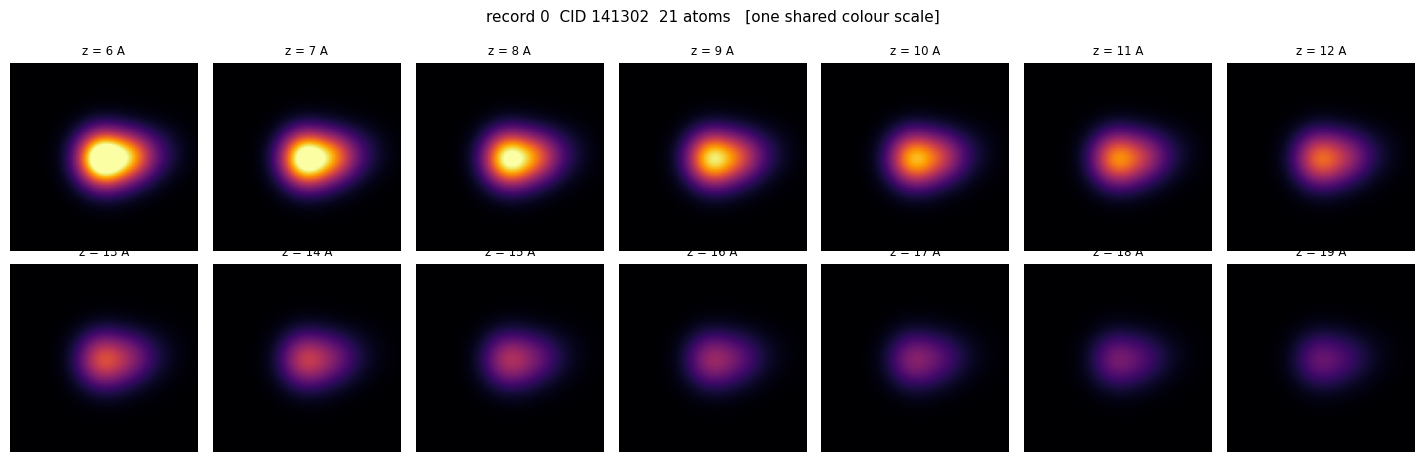

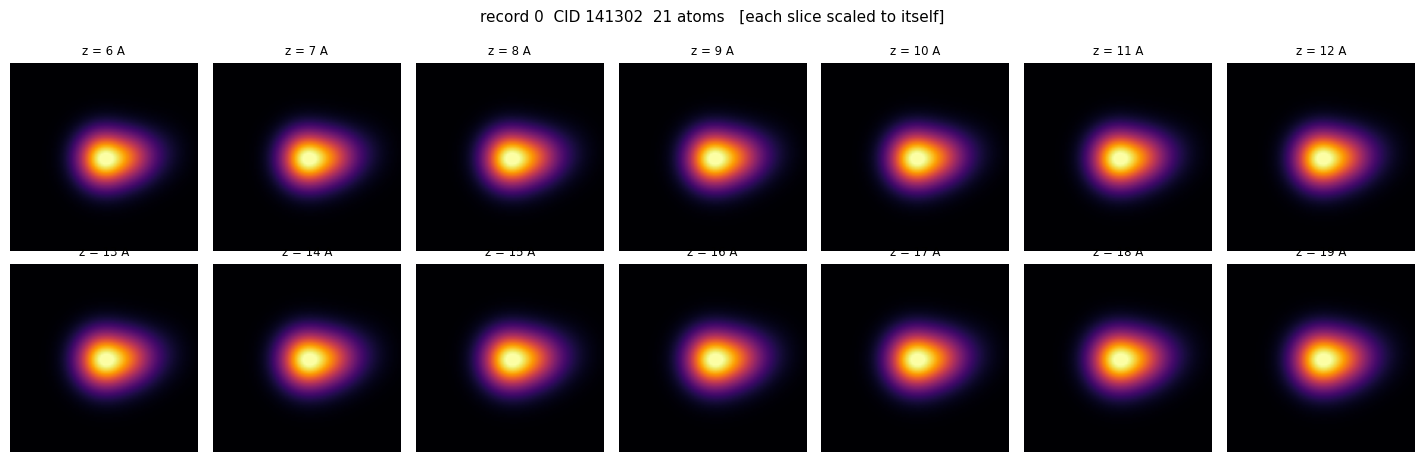

In [4]:
def cube_of(i, recover=True):
    """Cube for record row i.

    `recover` applies the file's own units conversion, X.astype(float32) * scale[i], which
    is what the group's `recover` attribute specifies."""
    c = np.asarray(X[i]).astype(np.float32)
    return c * float(SCALE[i]) if recover else c


def show_cube(i, per_slice=False, cmap='inferno', title=''):
    cube = cube_of(i)
    ncol = 7
    nrow = int(np.ceil(N_Z / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.05 * ncol, 2.3 * nrow))
    vmin, vmax = cube.min(), np.percentile(cube, 99.7)
    for k, ax in enumerate(np.ravel(axes)):
        ax.axis('off')
        if k >= N_Z:
            continue
        sl = cube[:, :, k]
        if per_slice:
            ax.imshow(sl, cmap=cmap, vmin=sl.min(), vmax=np.percentile(sl, 99.7))
        else:
            ax.imshow(sl, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(f'z = {Z_SLICES[k]:.0f} A', fontsize=8.5)
    fig.suptitle(title + ('   [each slice scaled to itself]' if per_slice
                          else '   [one shared colour scale]'), fontsize=11, y=1.0)
    fig.tight_layout()
    return fig


rec = records[0]
label = f'record {rec["h5_index"]}  CID {rec["cid"]}  {rec["num_atom"]} atoms'
show_cube(rec['h5_index'], per_slice=False, title=label)
show_cube(rec['h5_index'], per_slice=True, title=label)
plt.show()

## 3 - Gallery: the cube and the molecule it is paired with

Top row is the closest slice (z = 6 A, where contrast is strongest); bottom row is the molecule
from the sidecar, drawn heavy-atom-only. This is the pairing the model is trained on: cube in,
graph out.

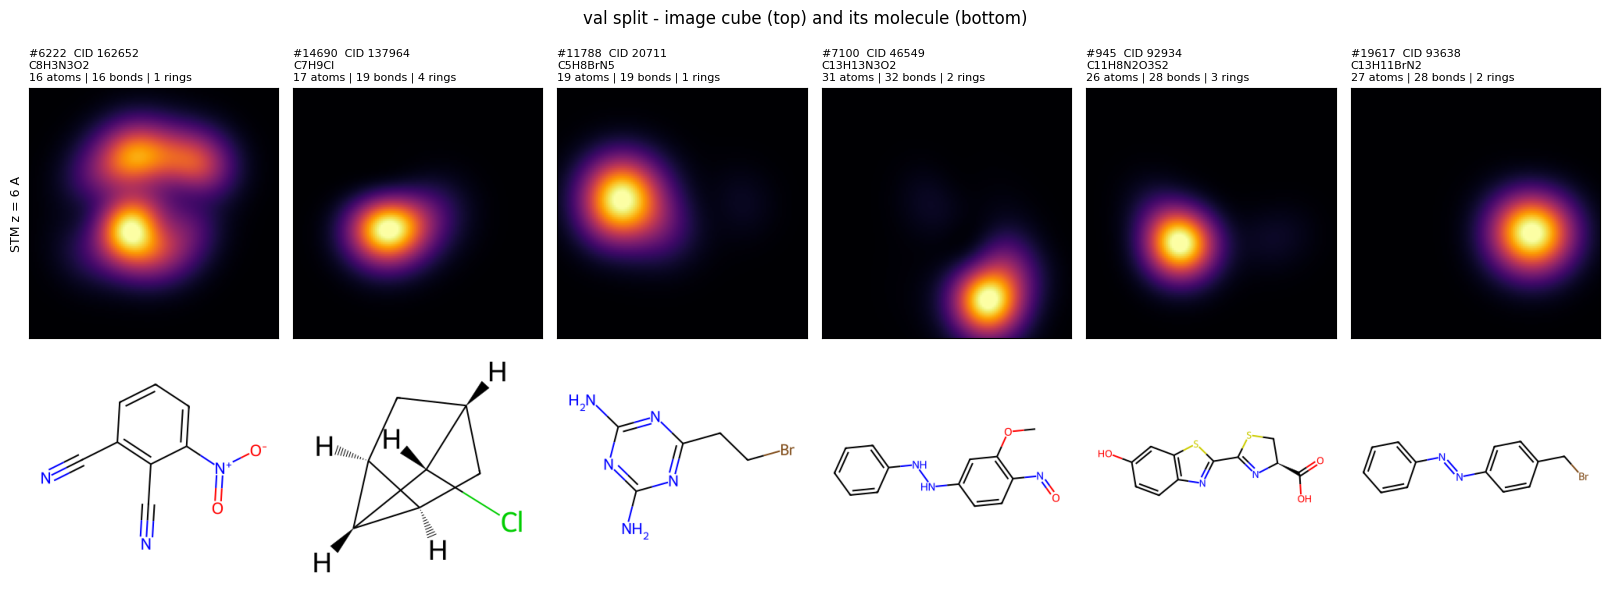

In [5]:
def describe(rec):
    m = prep(rec['rdmol'])                      # sanitize + remove H + 2D coords
    formula = CalcMolFormula(m) if m is not None else '?'
    n_bonds = rec['edge_index'].shape[1] // 2
    try:
        mm = Chem.Mol(rec['rdmol'])
        Chem.SanitizeMol(mm)
        n_rings = mm.GetRingInfo().NumRings()
    except Exception:
        n_rings = -1
    return m, (f'#{rec["h5_index"]}  CID {rec["cid"]}\n{formula}\n'
               f'{rec["num_atom"]} atoms | {n_bonds} bonds | {n_rings} rings')


def gallery(recs, slice_idx=0, cmap='inferno', suptitle=None):
    n = len(recs)
    fig, axes = plt.subplots(2, n, figsize=(2.7 * n, 6.2))
    axes = np.atleast_2d(axes)
    for c, rec in enumerate(recs):
        sl = cube_of(rec['h5_index'])[:, :, slice_idx]
        ax = axes[0, c]
        ax.imshow(sl, cmap=cmap, vmin=sl.min(), vmax=np.percentile(sl, 99.7))
        ax.set_xticks([]); ax.set_yticks([])
        mol, cap = describe(rec)
        ax.set_title(cap, fontsize=8, loc='left')

        ax = axes[1, c]
        ax.axis('off')
        if mol is not None:
            ax.imshow(np.asarray(Draw.MolToImage(mol, size=(320, 300))))
    axes[0, 0].set_ylabel(f'STM z = {Z_SLICES[slice_idx]:.0f} A', fontsize=9)
    fig.suptitle(suptitle or f'{SPLIT} split - image cube (top) and its molecule (bottom)',
                 fontsize=12, y=.99)
    fig.tight_layout()
    return fig


picks = [records[k] for k in rng.choice(len(records), N_GALLERY, replace=False)]
gallery(picks)
plt.show()

### The same molecule, imaged more than once

Because a record is an image rather than a molecule, the most-imaged CIDs give a free look at
what the conditioning encoder has to be invariant to: identical graph, different cube.

CID 205858: 29 records in this split, showing 6


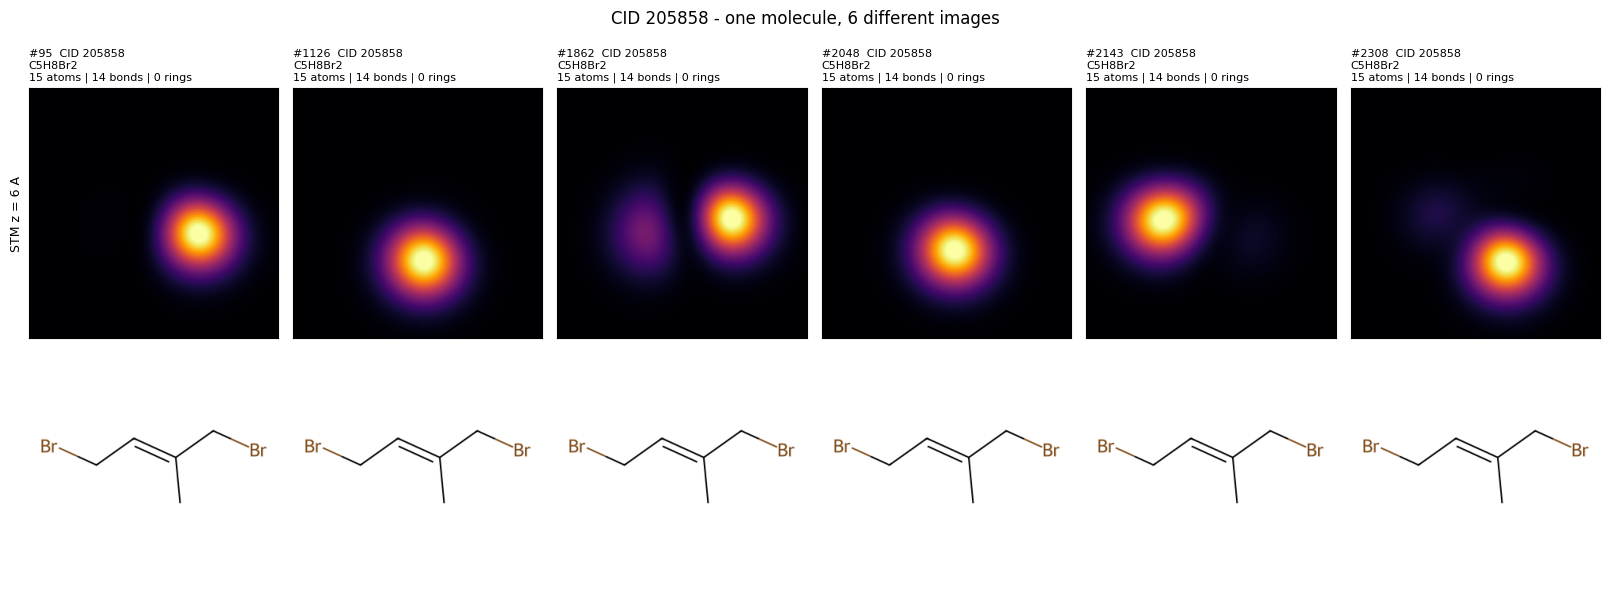

distinct SMILES across those 6 records: 1


In [6]:
top_cid = mult.most_common(1)[0][0]
same = [r for r in records if r['cid'] == top_cid][:6]
print(f'CID {top_cid}: {mult[top_cid]} records in this split, showing {len(same)}')
gallery(same, suptitle=f'CID {top_cid} - one molecule, {len(same)} different images')
plt.show()

# The graphs really are identical; only the image differs.
smis = set()
for r in same:
    m = Chem.Mol(r['rdmol'])
    Chem.SanitizeMol(m)
    smis.add(Chem.MolToSmiles(m))
print(f'distinct SMILES across those {len(same)} records: {len(smis)}')

## 4 - The z-envelope

Mean intensity per slice, one line per record. Monotone decay with tip height is the structural
property of this modality, and the reason the STM path does not reuse TERS's
`NormalizeVectorized`, which standardises each slice over `(H, W)` and would flatten every one
of these lines to horizontal.

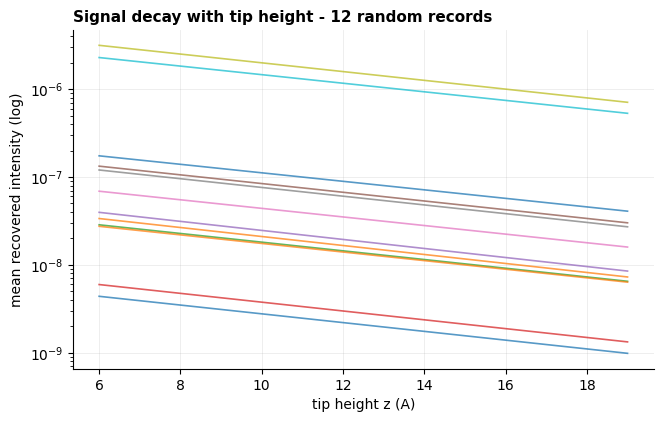

monotone decreasing in 12/12 records
median first/last ratio: 4x


In [7]:
sel = rng.choice(len(records), 12, replace=False)
env = np.stack([cube_of(records[k]['h5_index']).mean(axis=(0, 1)) for k in sel])

fig, ax = plt.subplots(figsize=(7.5, 4.4))
for row in env:
    ax.plot(Z_SLICES, row, lw=1.2, alpha=.75)
ax.set_yscale('log')
ax.set_xlabel('tip height z (A)')
ax.set_ylabel('mean recovered intensity (log)')
ax.set_title('Signal decay with tip height - 12 random records', fontsize=11, loc='left',
             fontweight='bold')
ax.grid(alpha=.25, lw=.6)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
plt.show()

n_mono = int((np.diff(env, axis=1) < 0).all(axis=1).sum())
print(f'monotone decreasing in {n_mono}/{len(sel)} records')
print(f'median first/last ratio: {np.median(env[:, 0] / env[:, -1]):.0f}x')

## 5 - Does the image line up with the coordinates?

**The file records no pixel-to-Angstrom mapping.** There is no field-of-view attribute, and the
TERS mapping that *is* recorded (`col = 127 + 14.2*x`, docs/05-progress-log.md) belongs to a
different corpus and does not transfer.

So it gets measured rather than assumed (docs/06-code-practices.md section 4). The probe below
renders heavy atoms as Gaussian blobs under a candidate `px = s*A + o` and scores each candidate
by correlation against the real image. **Read the number it prints before trusting the overlay:**
an overlay drawn from a guessed scale is worse than no overlay, because it looks like evidence
of alignment.

In [8]:
def render_atoms(a, s, o, sigma=3.0, hw=128):
    """Heavy atoms as Gaussian blobs under the candidate mapping px = s*A + o."""
    heavy = a[a[:, 3] > 1]
    if len(heavy) == 0:
        heavy = a[a[:, 3] > 0]
    cc, rr = s * heavy[:, 0] + o, s * heavy[:, 1] + o
    gy, gx = np.mgrid[0:hw, 0:hw]
    m = np.zeros((hw, hw), np.float32)
    for r_, c_ in zip(rr, cc):
        m += np.exp(-(((gy - r_) ** 2 + (gx - c_) ** 2) / (2 * sigma ** 2)))
    return m


def corr(a, b):
    a = a - a.mean(); b = b - b.mean()
    d = a.std() * b.std()
    return float((a * b).mean() / d) if d > 0 else 0.0


PROBE_N = 12
probe_idx = rng.choice(len(records), PROBE_N, replace=False)
probe = [(np.asarray(XYZ[records[k]['h5_index']]),
          cube_of(records[k]['h5_index'])[:, :, 0]) for k in probe_idx]

scores = {}
for s in np.arange(5.0, 12.1, 0.5):
    for o in np.arange(-40, 21, 5.0):
        scores[(s, o)] = float(np.mean([corr(render_atoms(a, s, o), img)
                                        for a, img in probe]))
(BEST_S, BEST_O), BEST_CORR = max(scores.items(), key=lambda kv: kv[1])
ranked = sorted(scores.values(), reverse=True)

print(f'best fit over {PROBE_N} records:  px = {BEST_S:.1f}*A + {BEST_O:.0f}   '
      f'mean correlation {BEST_CORR:.3f}')
print(f'implied field of view:  {128 / BEST_S:.1f} A across 128 px')
print(f'10th-best candidate scores {ranked[9]:.3f} - only {BEST_CORR - ranked[9]:.3f} worse')
print()
print('READ THIS BEFORE USING THE OVERLAY:')
print('  the correlation is positive but weak, and the fit is ill-conditioned - many (s, o)')
print('  that put the molecule centre near the image centre score almost identically. STM')
print('  contrast follows the frontier-orbital density, not the atom positions, so this is')
print('  an ESTIMATE of the mapping, not a verified registration. Good enough to say "the')
print('  molecule is centred and roughly this big"; NOT good enough to attribute a feature')
print('  in the image to a particular atom.')

best fit over 12 records:  px = 7.5*A + -10   mean correlation 0.433
implied field of view:  17.1 A across 128 px
10th-best candidate scores 0.424 - only 0.009 worse

READ THIS BEFORE USING THE OVERLAY:
  the correlation is positive but weak, and the fit is ill-conditioned - many (s, o)
  that put the molecule centre near the image centre score almost identically. STM
  contrast follows the frontier-orbital density, not the atom positions, so this is
  an ESTIMATE of the mapping, not a verified registration. Good enough to say "the
  molecule is centred and roughly this big"; NOT good enough to attribute a feature
  in the image to a particular atom.


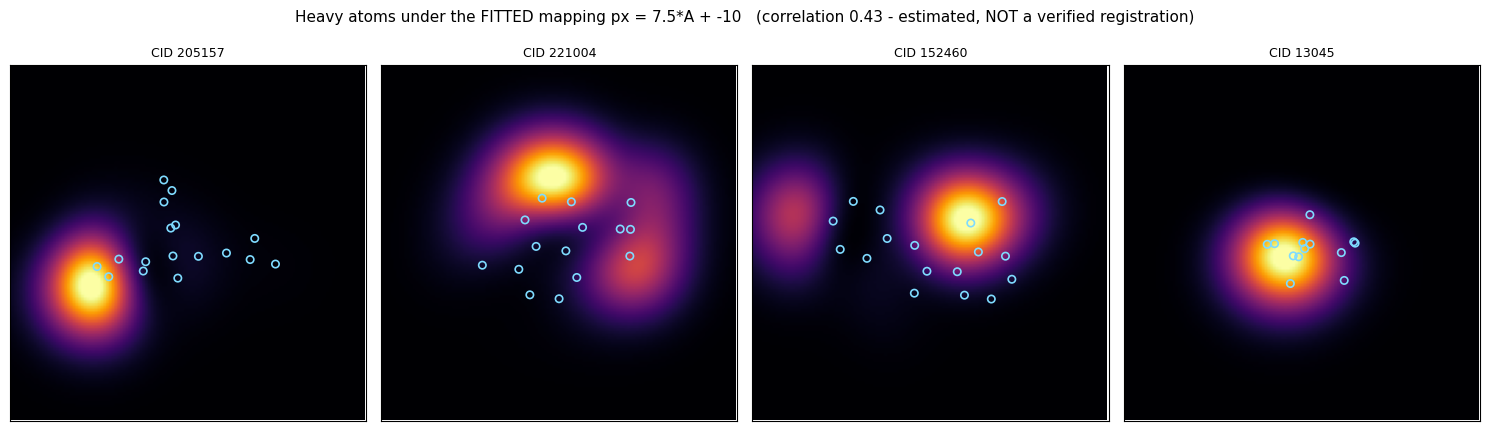

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, k in zip(axes, probe_idx[:4]):
    rec = records[k]
    a = np.asarray(XYZ[rec['h5_index']])
    a = a[a[:, 3] > 1]
    img = cube_of(rec['h5_index'])[:, :, 0]
    ax.imshow(img, cmap='inferno', vmin=img.min(), vmax=np.percentile(img, 99.7))
    ax.scatter(BEST_S * a[:, 0] + BEST_O, BEST_S * a[:, 1] + BEST_O,
               s=28, facecolors='none', edgecolors='#7fdbff', linewidths=1.2)
    ax.set_xlim(0, 128); ax.set_ylim(128, 0)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'CID {rec["cid"]}', fontsize=9)
fig.suptitle(f'Heavy atoms under the FITTED mapping px = {BEST_S:.1f}*A + {BEST_O:.0f}   '
             f'(correlation {BEST_CORR:.2f} - estimated, NOT a verified registration)',
             fontsize=11, y=1.02)
fig.tight_layout()
plt.show()

## 6 - Corpus-level figures

Produced by `tools/analyze_stm.py`. If they are not on disk yet:

```bash
module load python-pytorch/2.10
export PYTHONPATH="$HOME/.cache/ters-overlay:$PWD"
python3 tools/analyze_stm.py
```

In [10]:
from IPython.display import Image, display

ANALYSIS = under('stm-eval', 'analysis')
report_path = os.path.join(ANALYSIS, 'analysis.json')

if not os.path.exists(report_path):
    print(f'no report at {report_path} - run tools/analyze_stm.py first')
else:
    report = json.load(open(report_path))
    for split in ('train', 'val', 'test'):
        if split not in report:
            continue
        s, i = report[split], report[split]['identity']
        print(f'{split:6s} {i["n_records"]:>8,} records  {i["n_unique_cids"]:>7,} CIDs  '
              f'{i["records_per_cid"]:.2f} img/mol   '
              f'median {s["size"]["atoms"]["p50"]:.0f} atoms, '
              f'{s["molecular_weight"]["p50"]:.0f} g/mol')
        # .get, because a report written before planarity existed has no such key and
        # a KeyError here would hide every other number in this cell.
        pl = s.get('planarity')
        if not pl:
            continue
        pa, ph = pl['all_atoms'], pl['heavy_atoms']
        fr, frh = (pa['fraction_under_threshold'],
                   ph['fraction_under_threshold'])
        print(f'       planarity RMSD (SMARTERS): {pa["plane_rmsd"]["p50"]:.3f} A all-atom / '
              f'{ph["plane_rmsd"]["p50"]:.3f} A heavy   '
              + '  '.join(f'<={t}A {100 * fr[t]:.0f}%/{100 * frh[t]:.0f}%' for t in fr))
    if 'split_overlap' in report:
        ov = report['split_overlap']
        print(f'\n[{ov.get("severity", "?")}] {ov["verdict"]}')
        for pair, v in ov['pairs'].items():
            print(f'  {pair:12s} shared CIDs {v["shared_cids"]:>7,}   '
                  f'shared SMILES {v["shared_smiles"]:>7,}')

train   184,157 records   38,307 CIDs  4.81 img/mol   median 23 atoms, 218 g/mol
       planarity RMSD (SMARTERS): 0.725 A all-atom / 0.504 A heavy   <=0.05A 7%/19%  <=0.1A 8%/21%  <=0.5A 28%/50%
val      23,067 records    4,836 CIDs  4.77 img/mol   median 23 atoms, 218 g/mol
       planarity RMSD (SMARTERS): 0.725 A all-atom / 0.489 A heavy   <=0.05A 7%/19%  <=0.1A 9%/21%  <=0.5A 29%/51%
test     23,123 records    4,904 CIDs  4.72 img/mol   median 23 atoms, 218 g/mol
       planarity RMSD (SMARTERS): 0.716 A all-atom / 0.501 A heavy   <=0.05A 8%/20%  <=0.1A 9%/22%  <=0.5A 28%/50%

[structure_overlap] CID-disjoint, but 108 structures recur across splits under different CIDs (worst pair 1.20% of the smaller split)
  train|val    shared CIDs       0   shared SMILES      44
  train|test   shared CIDs       0   shared SMILES      59
  val|test     shared CIDs       0   shared SMILES       5


composition_test.png


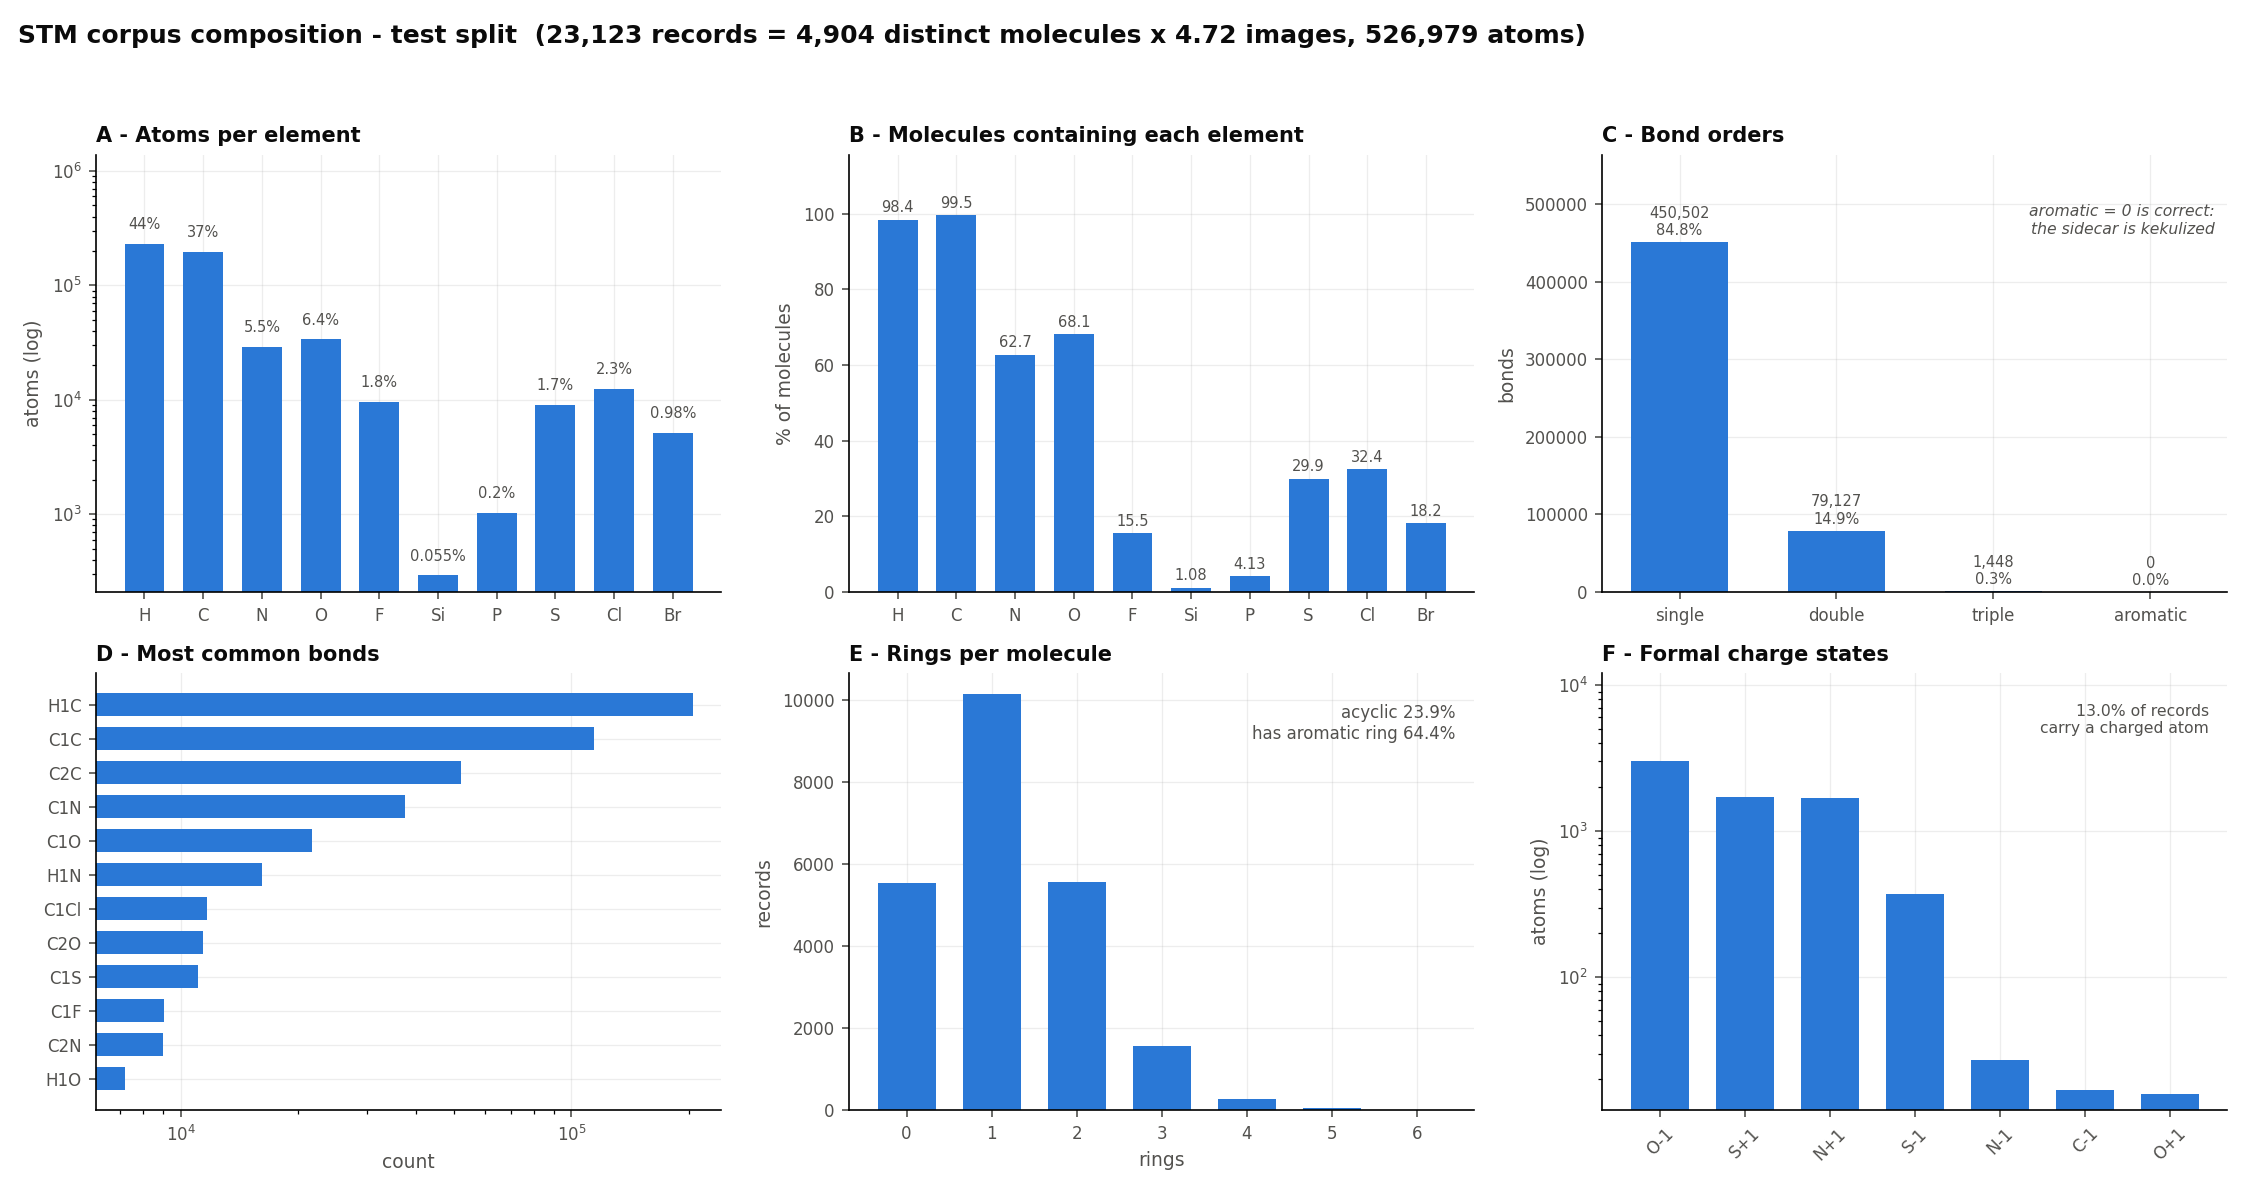

composition_train.png


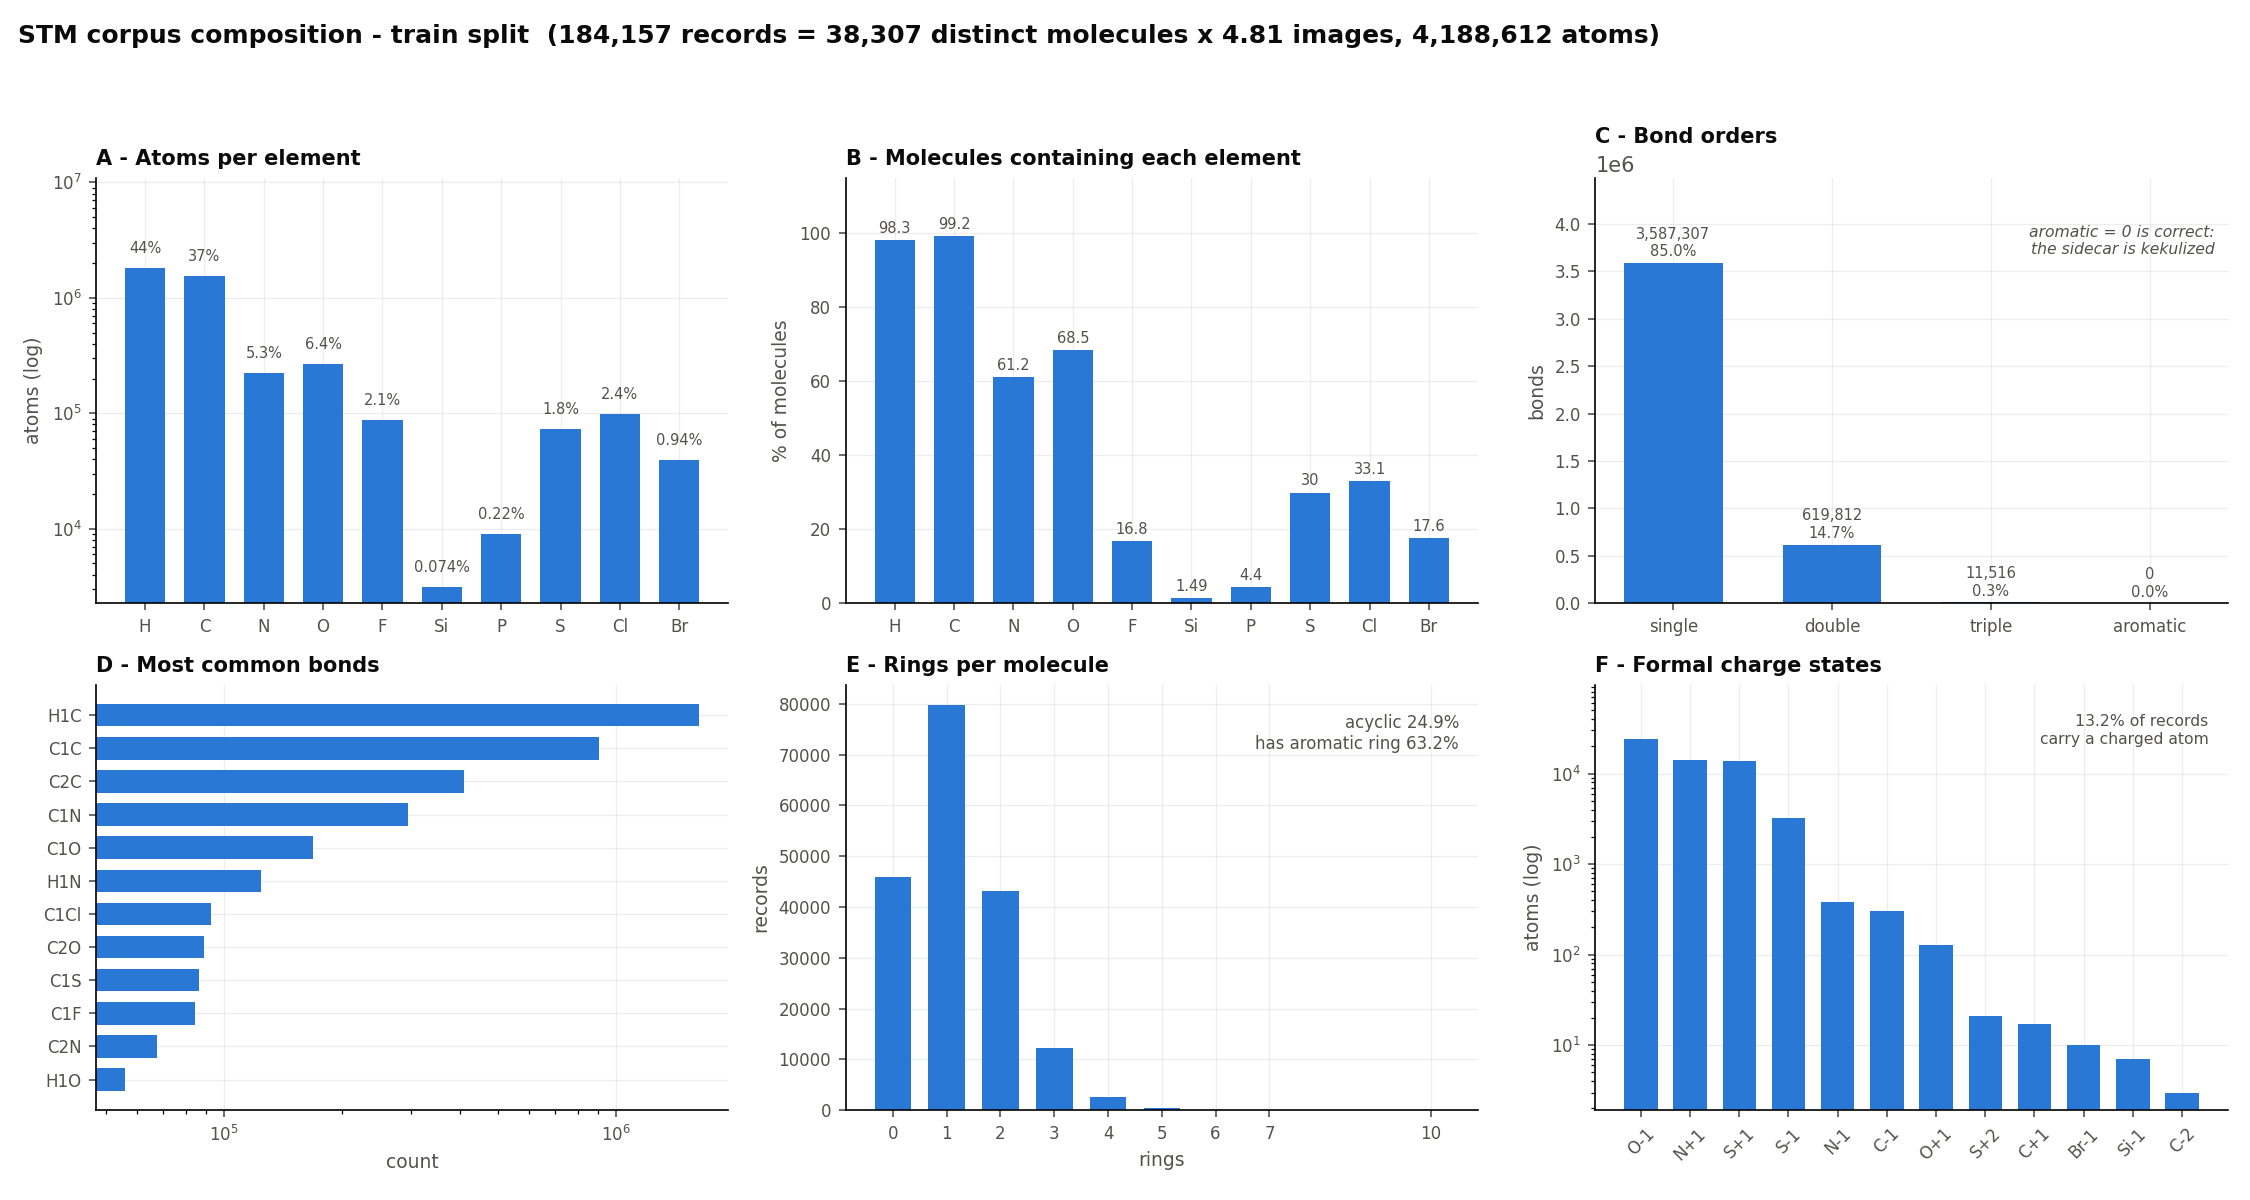

composition_val.png


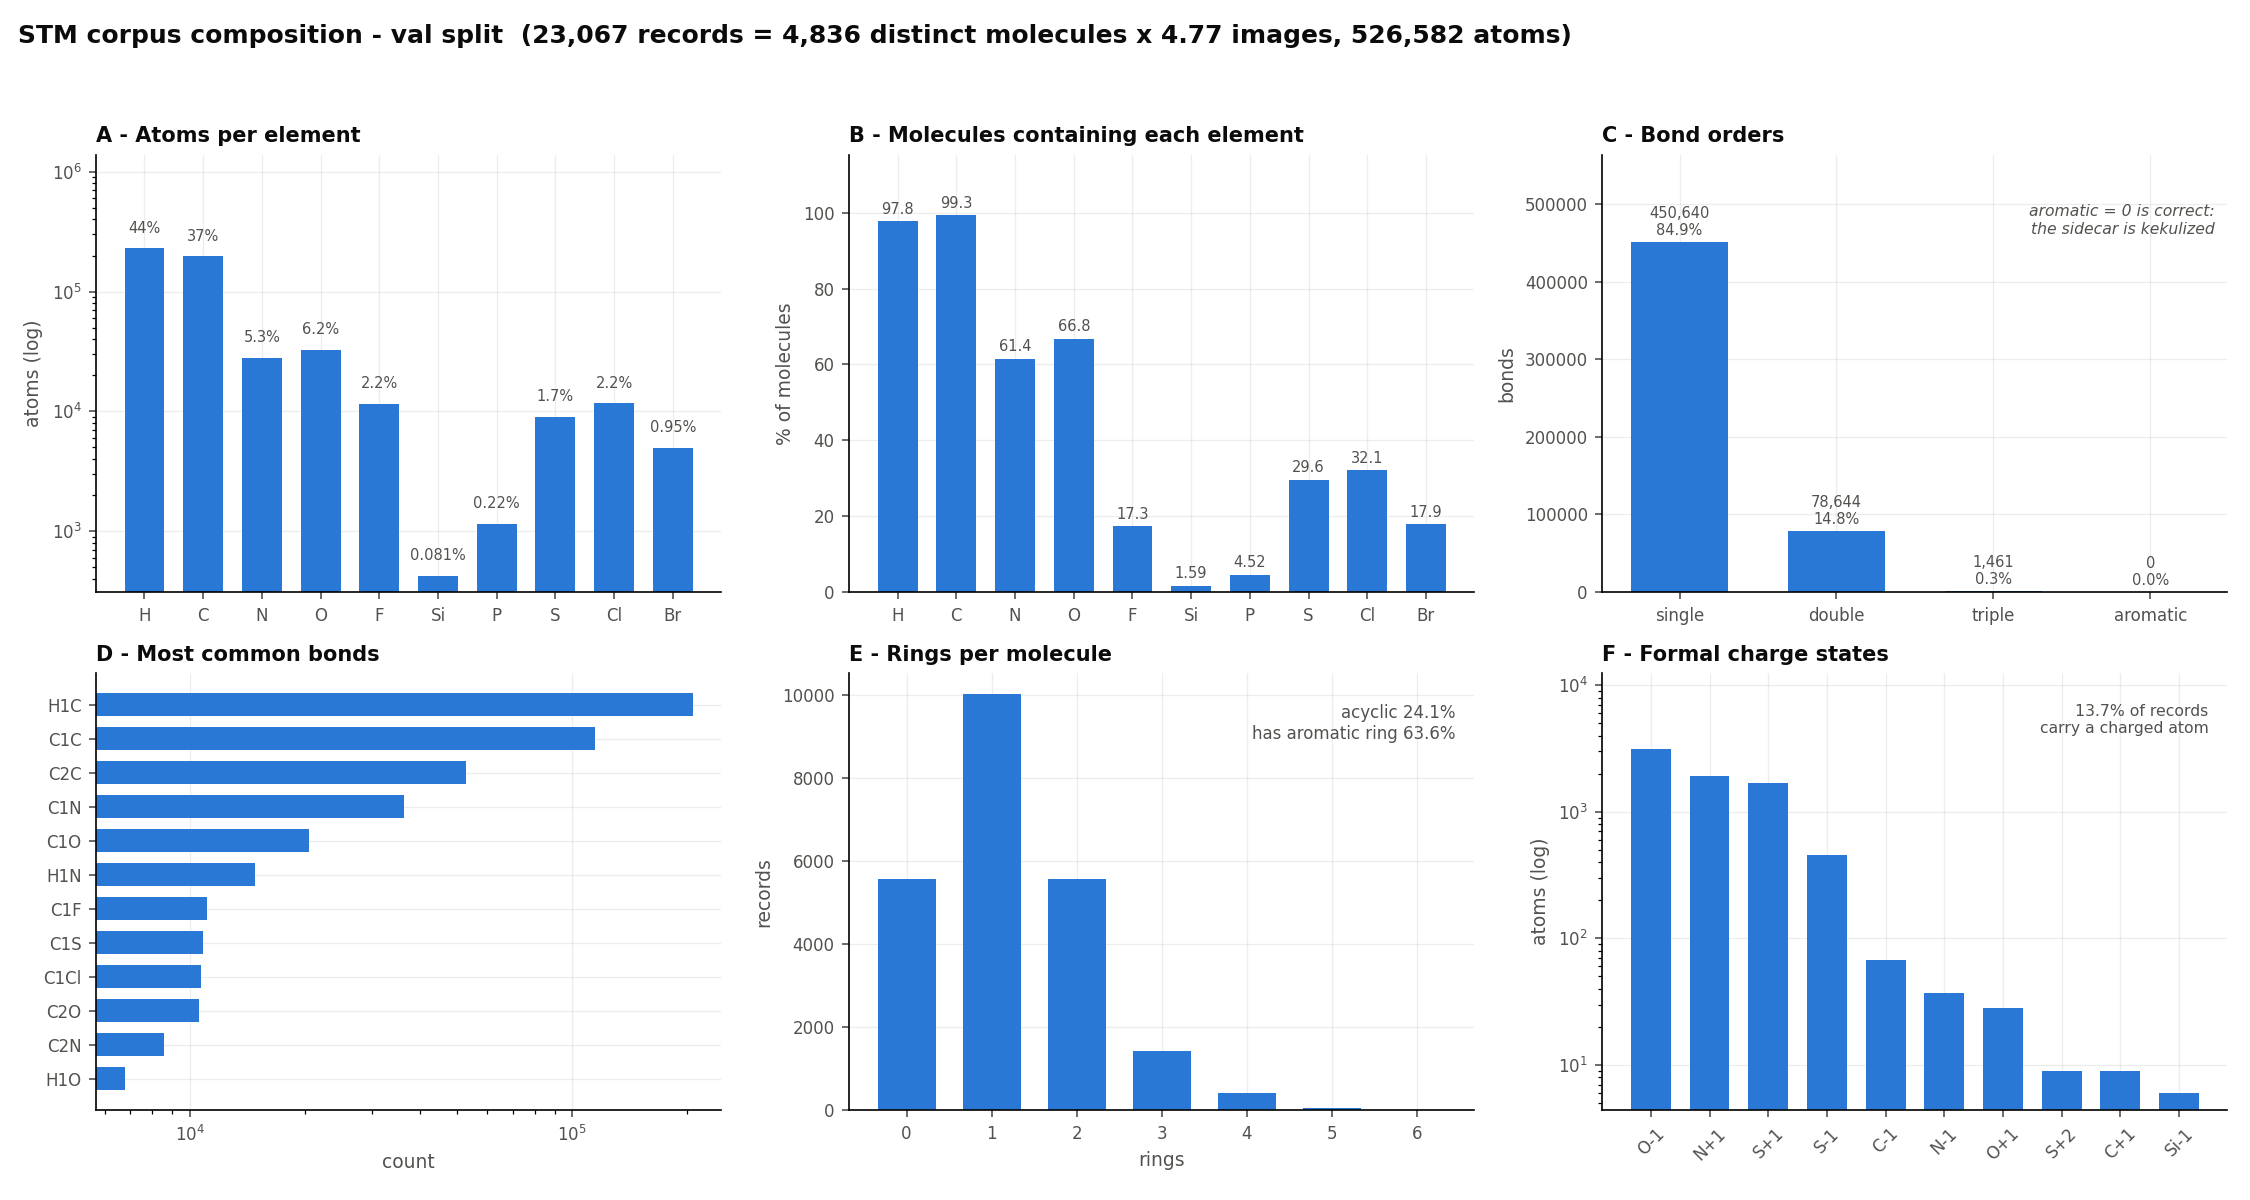

cubes.png


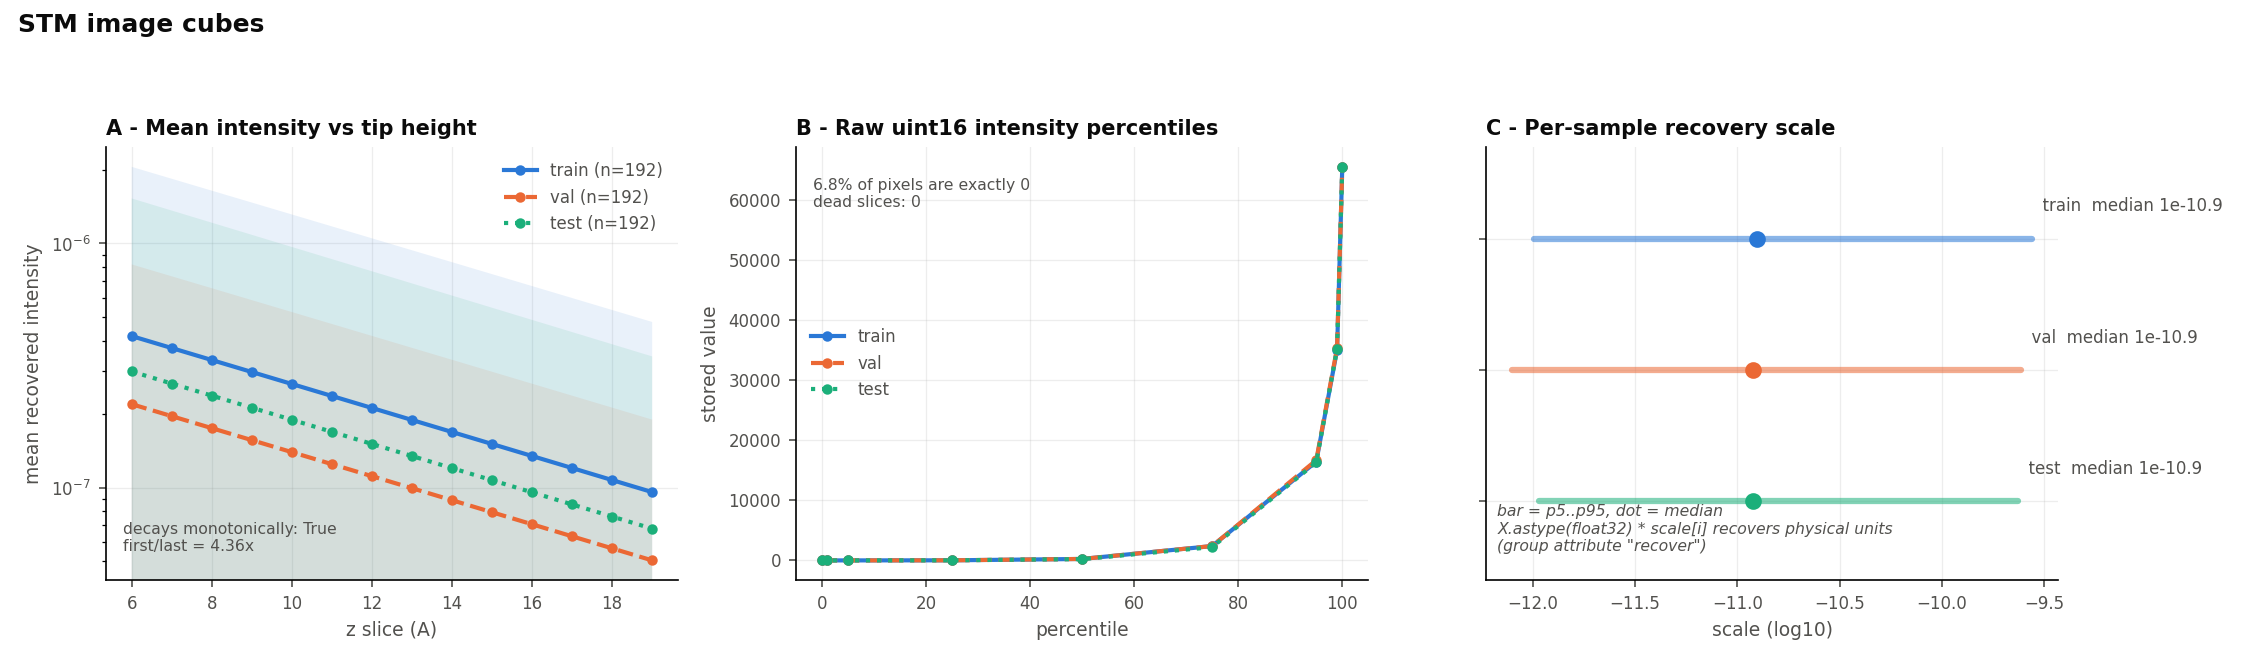

size_shape_test.png


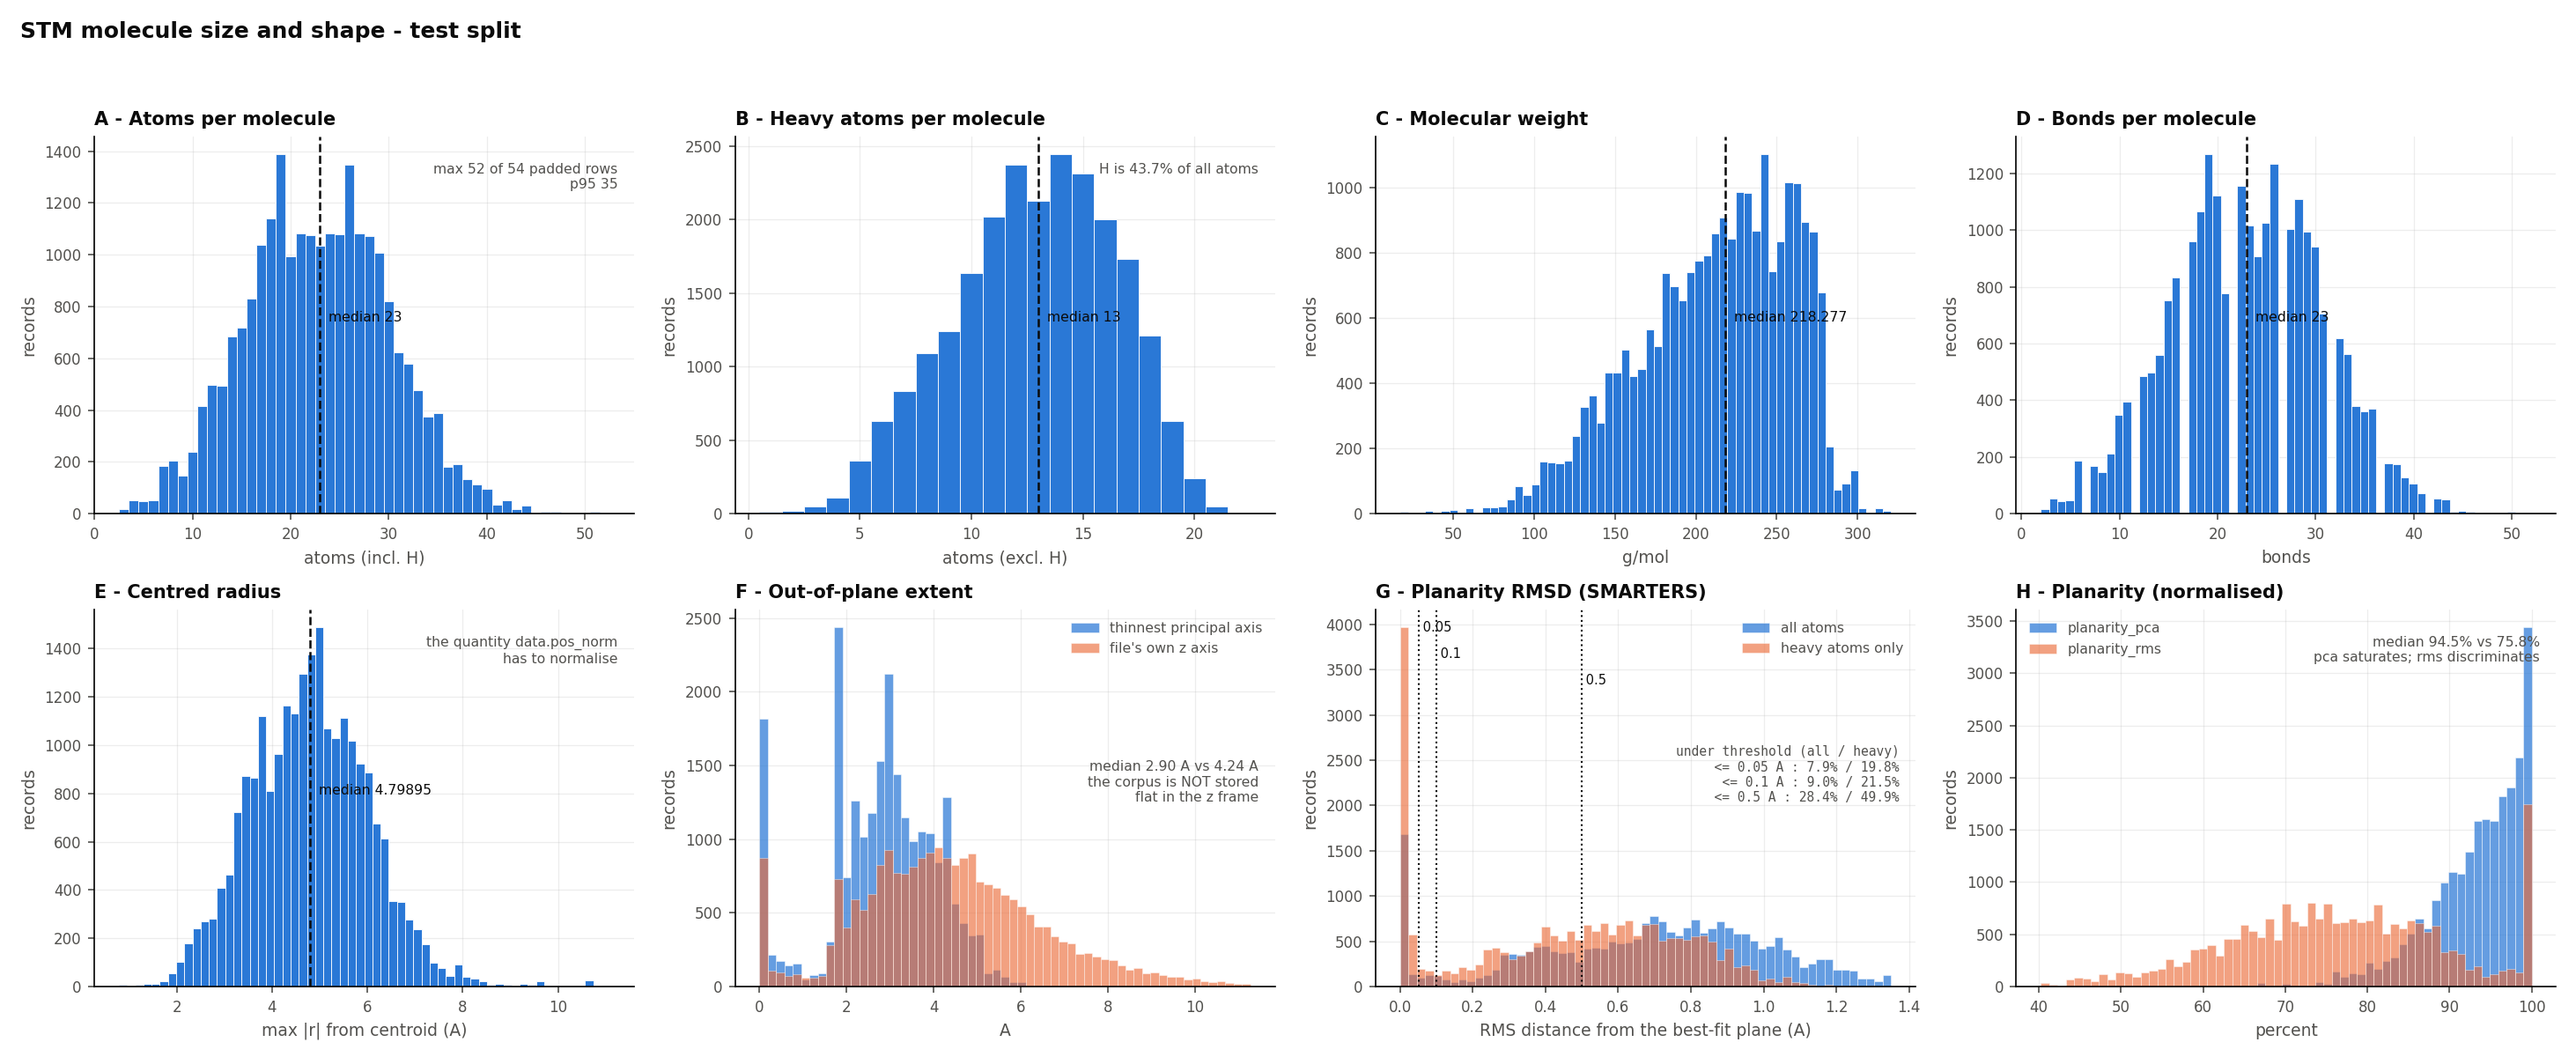

size_shape_train.png


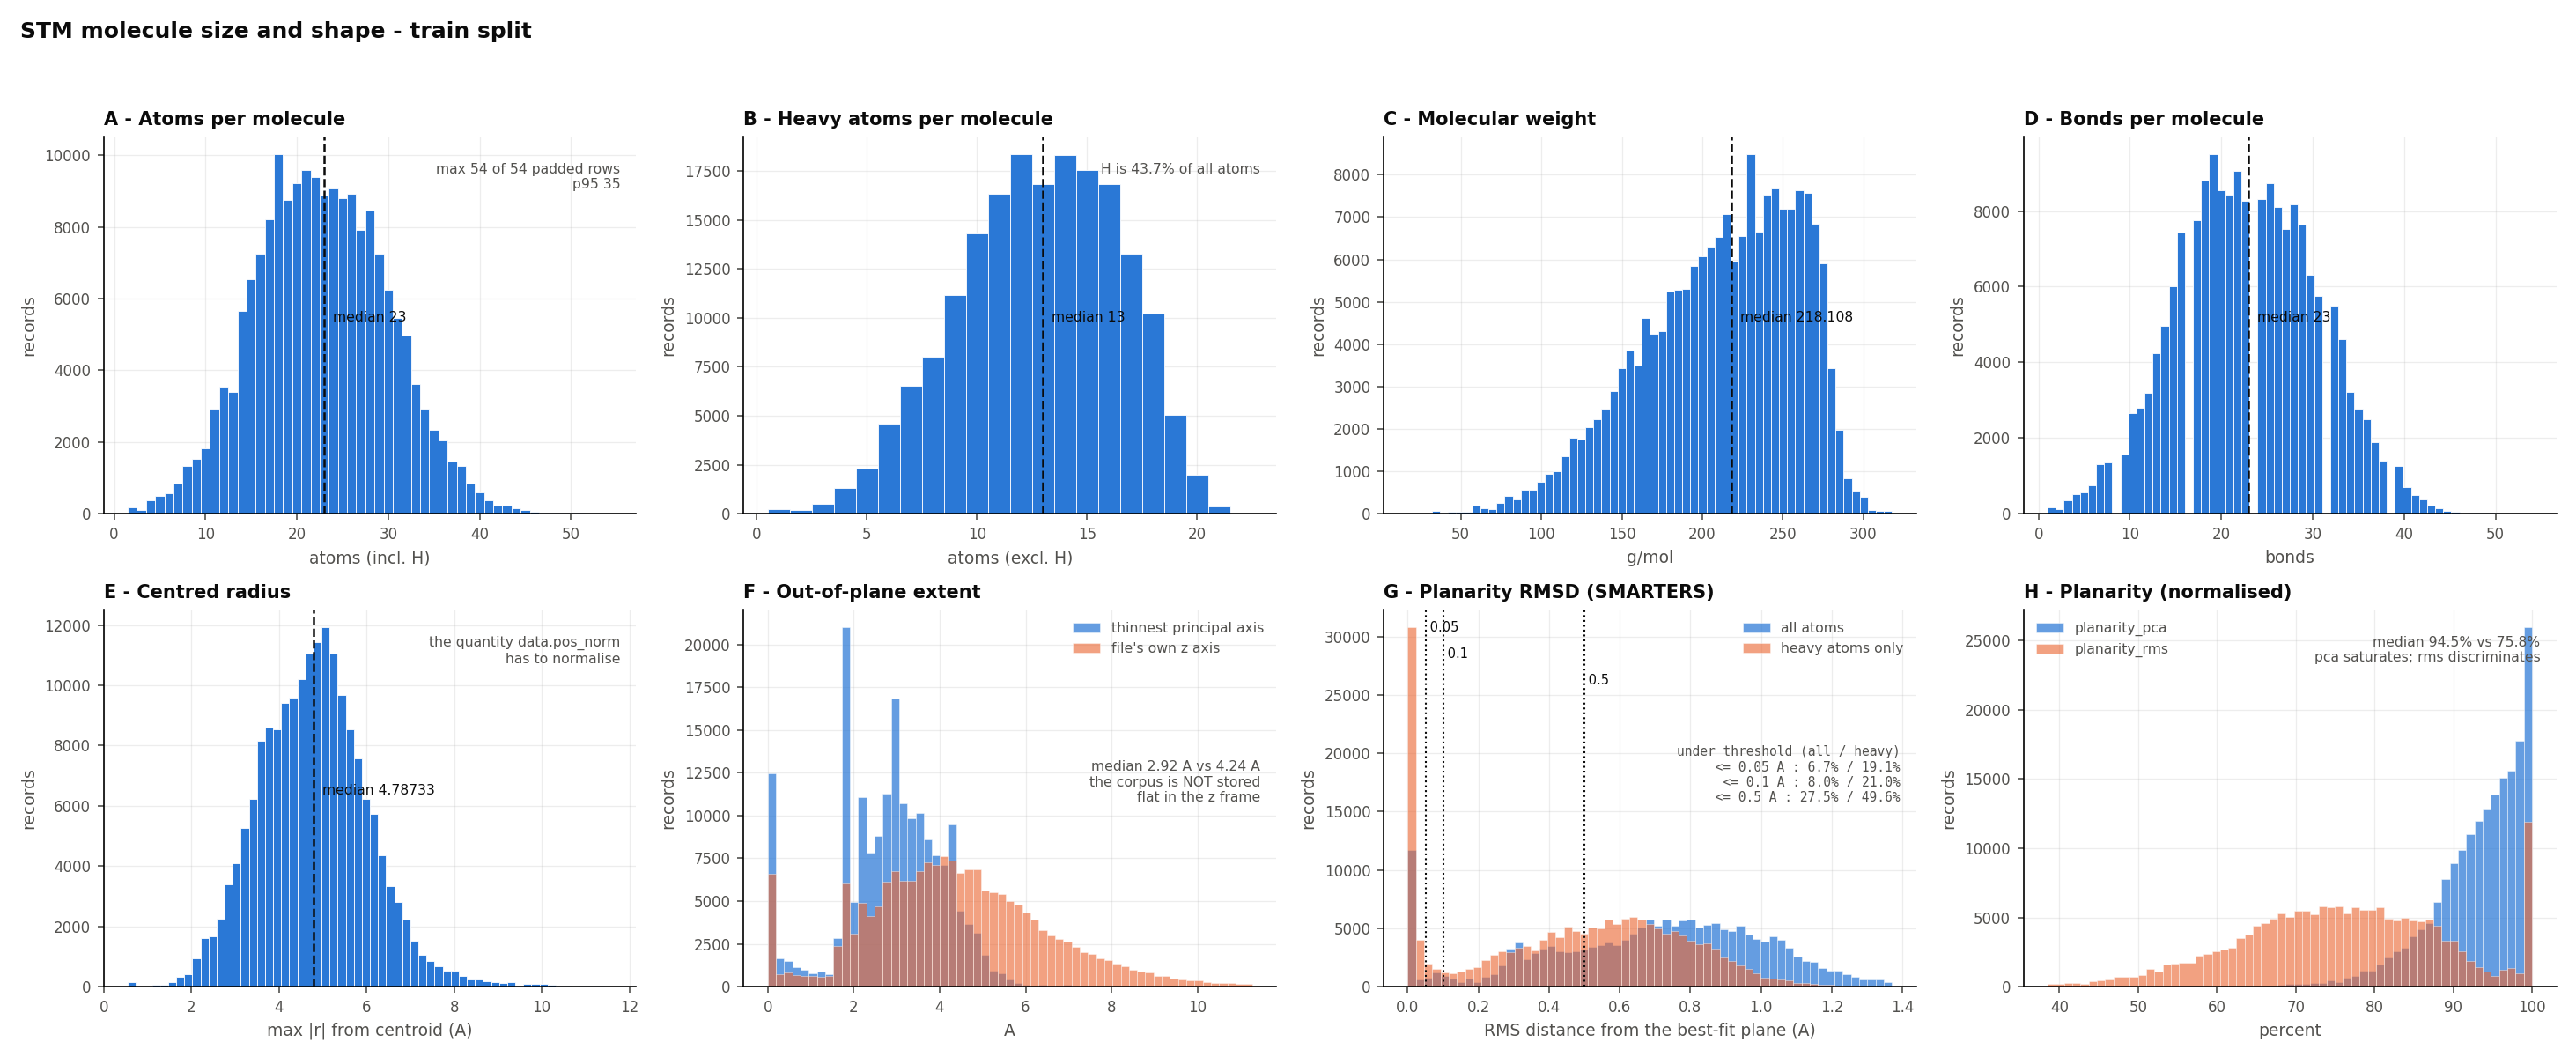

size_shape_val.png


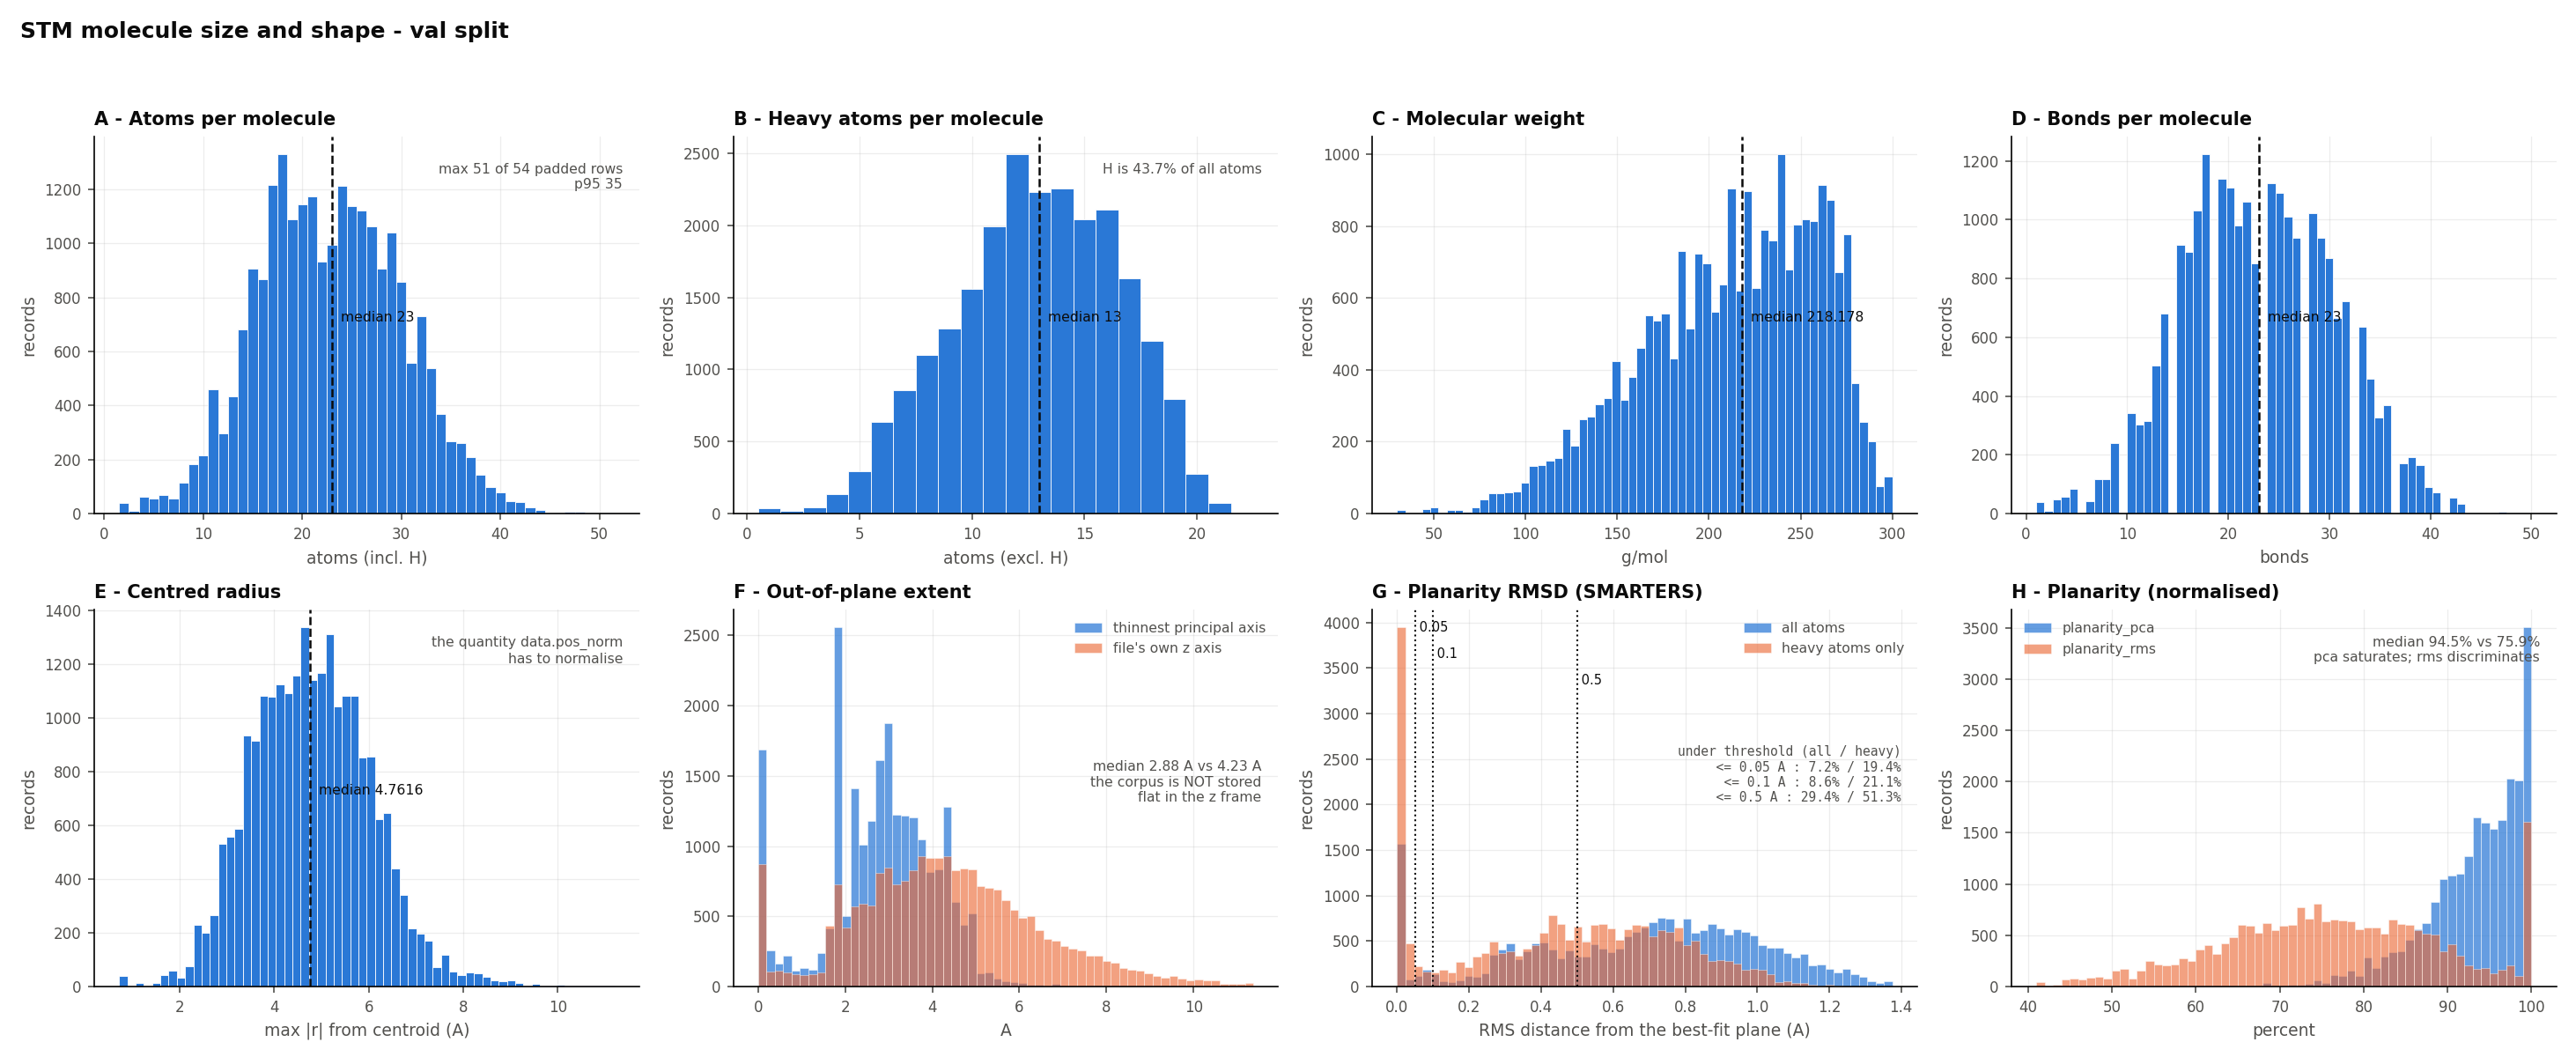

splits_comparison.png


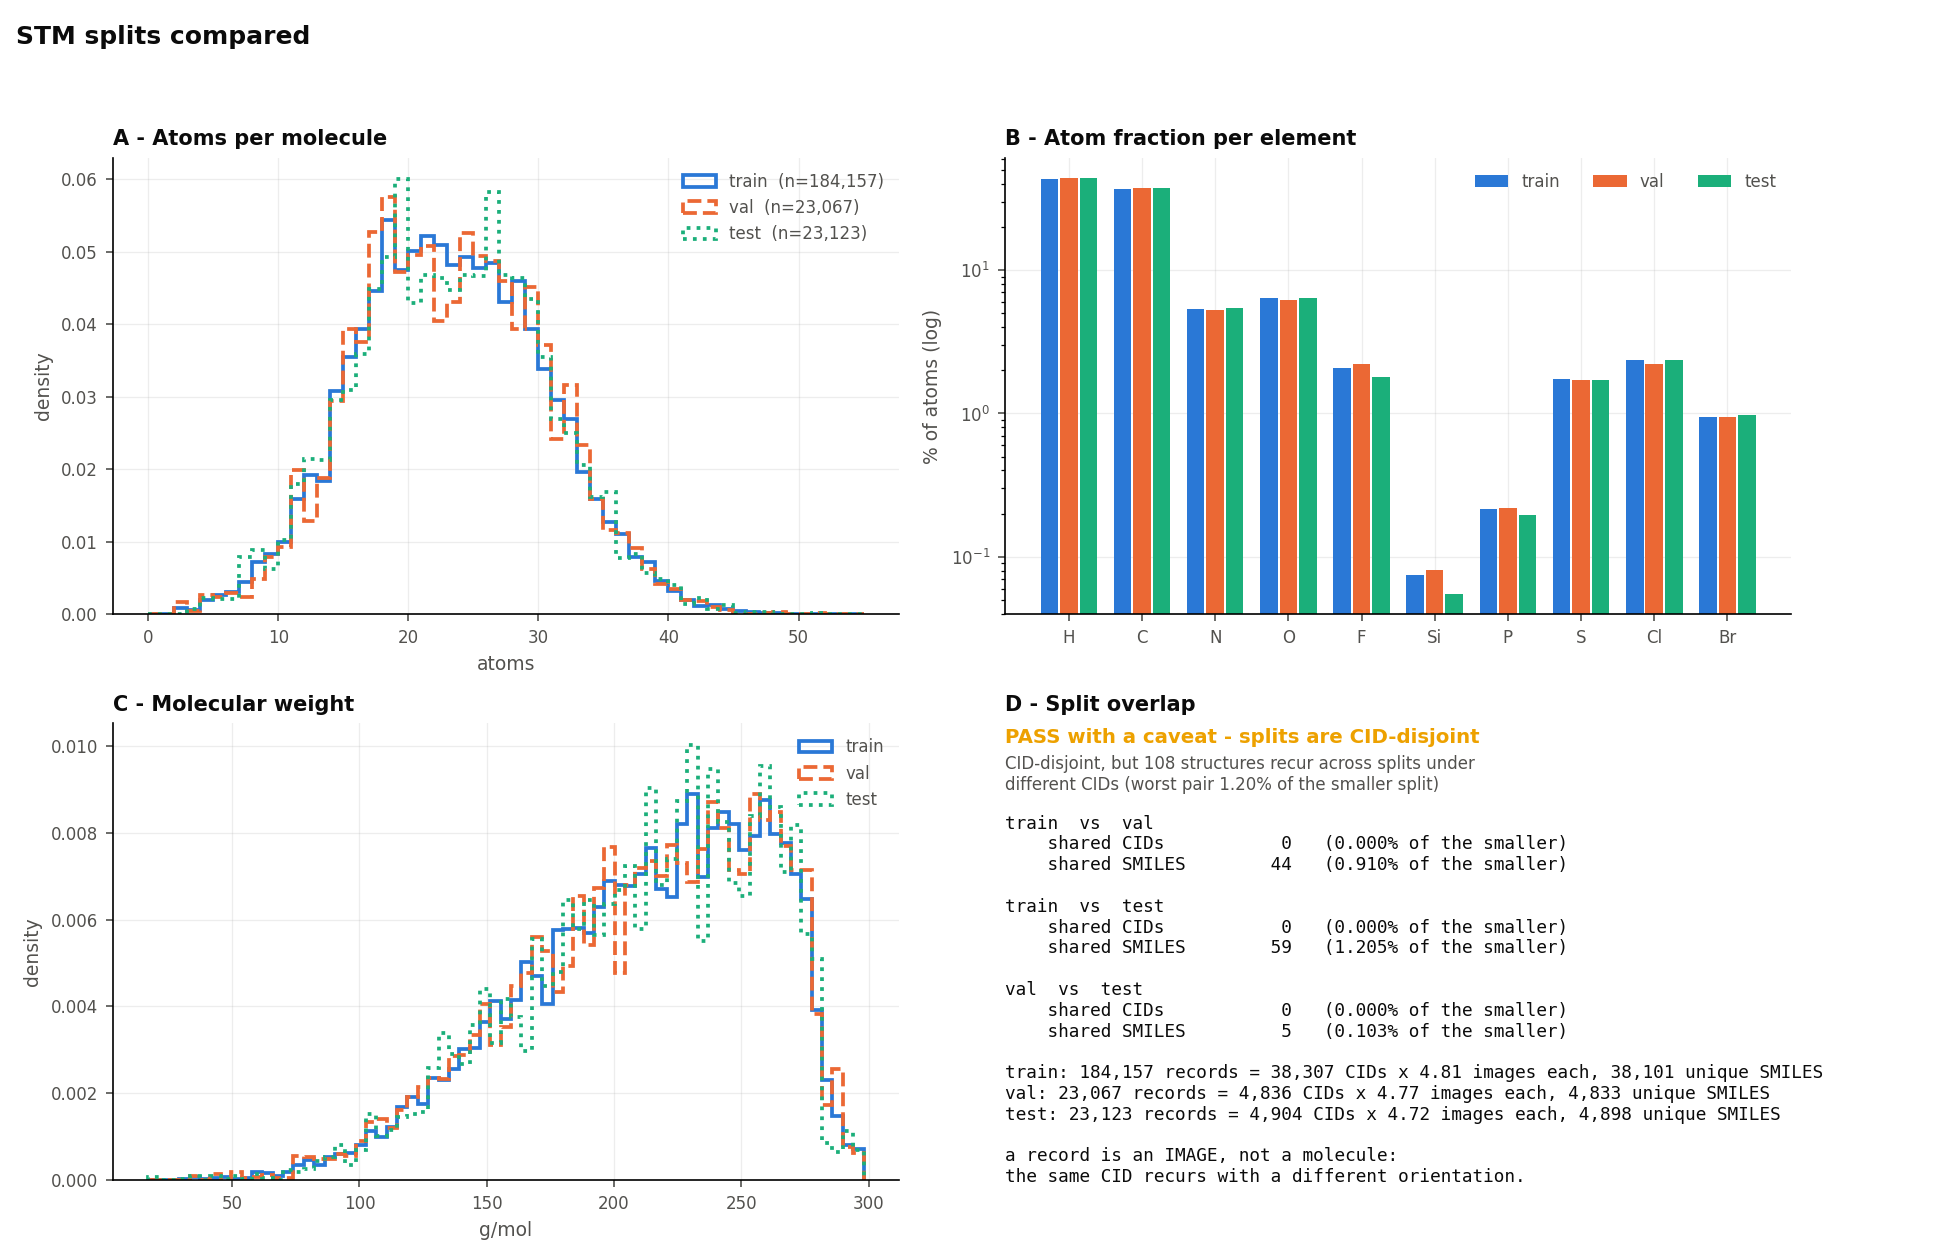

In [11]:
if os.path.exists(ANALYSIS):
    for name in sorted(os.listdir(ANALYSIS)):
        if name.endswith('.png'):
            print(name)
            display(Image(filename=os.path.join(ANALYSIS, name), width=1150))

In [12]:
f.close()
print('done')

done
